# Sustainable portfolio selection with QAOA, Part 1: penalty formulation

**Question.** A community pension fund puts its members' savings into exactly 3 of 6 sector funds, in equal amounts. Which 3 should it hold to balance return, risk and sustainability, and can QAOA find that choice?

This notebook addresses the four Track 2 tasks:

1. **Scenario:** who decides and who is affected (Section 1).
2. **Encoding:** the objective and the "exactly 3 funds" rule as a cost Hamiltonian with a penalty (Sections 2–4).
3. **Solve and verify:** QAOA in Qiskit, checked against brute force over all 64 possible choices (Sections 5–7).
4. **Reflect:** how the penalty weight changes what is actually being optimized (Sections 8–9).

Part 2 (`02_xy_mixer_and_tradeoffs.ipynb`) continues with a mixer that never breaks the rule, a better training protocol, and the sustainability trade-off. The code lives in `portfolio_qaoa.py`; `python portfolio_qaoa.py --part 1` prints this notebook's main results in a terminal.

## 1. Scenario: who decides, who is affected

- **Decision maker:** the fund's trustees. They set the weights in the objective: how much to care about risk ($\lambda$) and about sustainability ($\eta$).
- **People affected:** the members, whose retirement income depends on return and risk; and the communities affected by the companies the funds invest in.
- **The rule:** hold exactly $K = 3$ funds, in equal amounts (a simple diversification rule).

The six funds are illustrative, **not market data**. Funds A–C are carbon-intensive: higher expected return, low sustainability (ESG) score. Funds D–F are cleaner: lower return, higher ESG score. Risk comes from two shared factors: A–C rise and fall together (for example, commodity prices), and so do D–F (for example, clean-technology sentiment). Holding funds from both groups therefore lowers risk.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import qiskit
import portfolio_qaoa as pq

print("Qiskit", qiskit.__version__)
pf = pq.example_portfolio()   # lambda = 0.15, eta = 0
print(pq.table([{"fund": name, "expected return mu": m, "ESG score s": s, "variance Sigma_ii": var}
                for name, m, s, var in zip(pf.names, pf.mu, pf.esg, np.diag(pf.sigma))], digits=1))
print("\ncovariance matrix Sigma:\n", pf.sigma)

Qiskit 2.5.1
fund  expected return mu  ESG score s  variance Sigma_ii
----  ------------------  -----------  -----------------
   A                 9.0          1.0               10.0
   B                 8.0          2.0                7.5
   C                 7.0          5.0                6.0
   D                 6.0          8.0                6.0
   E                 5.0          9.0                7.5
   F                 4.0         10.0               10.0

covariance matrix Sigma:
 [[10.   7.5  6.   3.   1.5  0. ]
 [ 7.5  7.5  5.5  3.5  2.5  1.5]
 [ 6.   5.5  6.   4.   3.5  3. ]
 [ 3.   3.5  4.   6.   5.5  6. ]
 [ 1.5  2.5  3.5  5.5  7.5  7.5]
 [ 0.   1.5  3.   6.   7.5 10. ]]


## 2. The model in bits

One bit per fund: $x_i = 1$ means "hold fund $i$". With equal amounts, each held fund has weight $x_i / K$. The three quantities the trustees care about are

$$R(x) = \frac{1}{K}\mu^T x \ \text{(return)},\qquad V(x) = \frac{1}{K^2}x^T\Sigma x \ \text{(risk, the variance)},\qquad S(x) = \frac{1}{K}s^T x \ \text{(ESG score)}.$$

We **minimize** one number that trades them off:

$$f(x) = \lambda V(x) - R(x) - \eta S(x) \qquad\text{subject to}\qquad \sum_i x_i = K.$$

Return and ESG enter with a minus sign, because minimizing $-R$ maximizes $R$. This notebook uses $\lambda = 0.15$ and $\eta = 0$ (sustainability ignored); Part 2 varies $\eta$.

With 6 funds there are only $2^6 = 64$ bitstrings, and $\binom{6}{3} = 20$ of them hold exactly 3 funds, so a computer can check them all. That brute-force answer is the reference every quantum result is checked against.

In [2]:
ex = pq.brute_force(pf)
print(f"{len(ex.f)} bitstrings, {ex.feasible.sum()} valid portfolios (exactly {pf.k} funds)\n")
print("Best valid portfolios:")
print(pq.table(ex.ranking(top=5)))
print(f"\nOptimum: {ex.best} with f* = {ex.f_star:.3f}")

64 bitstrings, 20 valid portfolios (exactly 3 funds)

Best valid portfolios:
assets  return   risk    ESG       f
------  ------  -----  -----  ------
   ABC   8.000  6.833  2.667  -6.975
   ABD   7.667  5.722  3.667  -6.808
   ACD   7.333  5.333  4.667  -6.533
   ABE   7.333  5.333  4.000  -6.533
   BCD   7.000  5.056  5.000  -6.242

Optimum: ABC with f* = -6.975


The optimum ABC holds the three highest-return funds. It also has the highest risk of the top five, because A, B and C move together, but at $\lambda = 0.15$ return matters more. The runner-up ABD is only $0.167$ worse, which makes the optimum hard for QAOA to single out.

## 3. The rule "exactly 3 funds" as a penalty

The standard QAOA circuit can produce any bitstring, so the rule has to be built into the cost. We add a penalty that is zero for valid portfolios and grows with the size of the violation:

$$F_A(x) = f(x) + A\Big(\sum_i x_i - K\Big)^2 .$$

Holding 2 or 4 funds costs $A$ extra; holding 1 or 5 costs $4A$.

**How big must $A$ be?** Write $v(x) = (\sum_i x_i - K)^2$. An invalid $x$ beats the best valid portfolio when $f(x) + A\,v(x) < f^*$. Solving for $A$, every invalid bitstring loses only if

$$A > A_{crit} = \max_{x\ \text{invalid}} \frac{f^* - f(x)}{v(x)} .$$

Below $A_{crit}$ the lowest-energy state breaks the rule, so even a perfect quantum solver would return an invalid portfolio.

In [3]:
v = (ex.X.sum(axis=1) - pf.k) ** 2
A_crit = pq.critical_penalty(ex)
print(f"A_crit = {A_crit:.3f}\n")
rows = []
for A_value in [1.0, A_crit, 2.0, 4.0]:
    F_values = ex.f + A_value * v
    winners = np.flatnonzero(np.isclose(F_values, F_values.min(), rtol=0, atol=1e-9))
    rows.append({"A": A_value, "lowest F": F_values.min(),
                 "lowest-F bitstring(s)": ", ".join(pq.assets(pf, ex.X[i]) for i in winners),
                 "valid?": " / ".join(str(bool(ex.feasible[i])) for i in winners)})
print(pq.table(rows))

A_crit = 1.550

    A  lowest F  lowest-F bitstring(s)        valid?
-----  --------  ---------------------  ------------
1.000    -7.525                   ABCD         False
1.550    -6.975              ABC, ABCD  True / False
2.000    -6.975                    ABC          True
4.000    -6.975                    ABC          True


At $A = 1$ the lowest-energy state is ABCD, four funds: a fourth high-return fund is worth more than the penalty, so the minimum violates the diversification rule. At $A_{crit} = 1.55$, ABC and ABCD tie. We use $A = 2$, just above the threshold; Section 8 examines how this choice affects QAOA.

### Choosing $A$ without knowing the answer

$A_{crit}$ used the brute-force optimum $f^*$, which is not available for a real problem. A bound that does not require the optimum is obtained as follows. Take any valid portfolio's cost $U \ge f^*$ (here, from a greedy heuristic) and a lower bound $L \le f(x)$ over all bitstrings (here, the constant plus every negative QUBO coefficient). An invalid $x$ has $v(x) \ge 1$, so

$$F_A(x) \ \ge\ L + A \ >\ U \ \ge\ f^* \qquad\text{whenever}\qquad A > U - L .$$

In [4]:
bound = pq.safe_penalty(pf)
print(f"U = {bound['U']:.3f} (greedy portfolio), L = {bound['L']:.3f}  ->  any A > U - L = {bound['A_safe']:.2f} is safe")
print(f"exact threshold from brute force: A_crit = {A_crit:.2f}")

U = -6.975 (greedy portfolio), L = -12.217  ->  any A > U - L = 5.24 is safe
exact threshold from brute force: A_crit = 1.55


The guaranteed-safe penalty, $A > 5.24$, is more than three times $A_{crit} = 1.55$. Section 8 shows what a penalty that large does to QAOA: almost every sample is valid, but the best portfolio is barely more likely than a random valid pick. Guaranteeing the rule without knowing the answer therefore places the penalty method in its least effective regime, which motivates the XY mixer used in Part 2.

## 4. From the cost function to a Hamiltonian

**Step 1: expand into a QUBO** (a constant, plus linear and pairwise terms). For bits $x_i^2 = x_i$, so

$$x^T\Sigma x = \sum_i \Sigma_{ii}x_i + 2\sum_{i<j}\Sigma_{ij}x_ix_j,\qquad \Big(\sum_i x_i - K\Big)^2 = \sum_i (1-2K)\,x_i + 2\sum_{i<j}x_ix_j + K^2 .$$

Collecting terms gives $F_A(x) = c + \sum_i a_i x_i + \sum_{i<j} b_{ij}x_ix_j$ with

$$a_i = \frac{\lambda\Sigma_{ii}}{K^2} - \frac{\mu_i}{K} - \frac{\eta s_i}{K} + A(1-2K),\qquad b_{ij} = \frac{2\lambda\Sigma_{ij}}{K^2} + 2A,\qquad c = AK^2 .$$

**Step 2: bits to spins.** Qiskit's $Z$ has eigenvalue $+1$ on $|0\rangle$ and $-1$ on $|1\rangle$, so $x_i = (1 - Z_i)/2$ and

$$x_i \to \tfrac12 - \tfrac12 Z_i,\qquad x_ix_j \to \tfrac14\left(1 - Z_i - Z_j + Z_iZ_j\right).$$

This gives $H = \sum_i h_i Z_i + \sum_{i<j} J_{ij} Z_iZ_j$ plus a constant $C$:

$$h_i = -\frac{a_i}{2} - \frac14\sum_{j\ne i} b_{ij},\qquad J_{ij} = \frac{b_{ij}}{4},\qquad C = c + \frac12\sum_i a_i + \frac14\sum_{i<j} b_{ij}.$$

The constant only adds a global phase in the circuit, so it is kept aside and added back when comparing energies. The cell below builds $H$ for $A = 2$ and checks it against $F_A$ on all 64 bitstrings.

In [5]:
A = 2.0
H, offset = pq.cost_hamiltonian(pf, A)
print(H)
print(f"\nconstant C = {offset:.4f}")
F = ex.f + A * v
print("diag(H) + C equals F_A(x) for all 64 bitstrings:", np.allclose(pq.diagonal(H) + offset, F))

J = {tuple(int(i) for i in np.flatnonzero(P.z)): c.real for P, c in zip(H.paulis, H.coeffs) if P.z.sum() == 2}
risk_part = [value - A / 2 for value in J.values()]
print(f"\nZZ coefficients: penalty part {A / 2:.3f} on every pair; "
      f"risk part between {min(risk_part):.4f} and {max(risk_part):.4f}")

SparsePauliOp(['IIIIIZ', 'IIIIZI', 'IIIZII', 'IIZIII', 'IZIIII', 'ZIIIII', 'IIIIZZ', 'IIIZIZ', 'IIZIIZ', 'IZIIIZ', 'ZIIIIZ', 'IIIZZI', 'IIZIZI', 'IZIIZI', 'ZIIIZI', 'IIZZII', 'IZIZII', 'ZIIZII', 'IZZIII', 'ZIZIII', 'ZZIIII'],
              coeffs=[1.26666667+0.j, 1.1       +0.j, 0.93333333+0.j, 0.76666667+0.j,
 0.6       +0.j, 0.43333333+0.j, 1.0625    +0.j, 1.05      +0.j,
 1.025     +0.j, 1.0125    +0.j, 1.        +0.j, 1.04583333+0.j,
 1.02916667+0.j, 1.02083333+0.j, 1.0125    +0.j, 1.03333333+0.j,
 1.02916667+0.j, 1.025     +0.j, 1.04583333+0.j, 1.05      +0.j,
 1.0625    +0.j])

constant C = -2.6042
diag(H) + C equals F_A(x) for all 64 bitstrings: True

ZZ coefficients: penalty part 1.000 on every pair; risk part between 0.0000 and 0.0625


The penalty adds $A/2 = 1$ to every $ZZ$ coefficient, while risk contributes at most $0.0625$: the penalty terms are 16 times larger than the risk terms. Before building the circuit, `pq.QAOA` divides $H$ by its largest coefficient, so the angle $\gamma$ is measured in units where the strongest term is 1. This does not change which bitstring is best.

## 5. The QAOA circuit

$$|\psi(\gamma,\beta)\rangle = \prod_{k=1}^{p} e^{-i\beta_k\sum_i X_i}\, e^{-i\gamma_k H}\, |+\rangle^{\otimes 6}$$

- **Start:** $|+\rangle^{\otimes 6}$, an equal superposition of all 64 bitstrings (a Hadamard on every qubit).
- **Cost layer** $e^{-i\gamma H}$: all terms of $H$ commute, so it splits exactly into gates, $R_Z(2\gamma h_i)$ on qubit $i$ and $R_{ZZ}(2\gamma J_{ij})$ on each pair. It only changes phases.
- **Mixer layer** $e^{-i\beta\sum_i X_i}$: $R_X(2\beta)$ on every qubit. It turns phase differences into probability differences (interference).
- **Depth** $p$ is the number of cost + mixer rounds, so there are $2p$ angles.

The cell below checks the circuit against Qiskit's built-in `QAOAAnsatz` and draws it for $p = 1$.

|<this circuit | Qiskit QAOAAnsatz>| at p = 3: 1.0


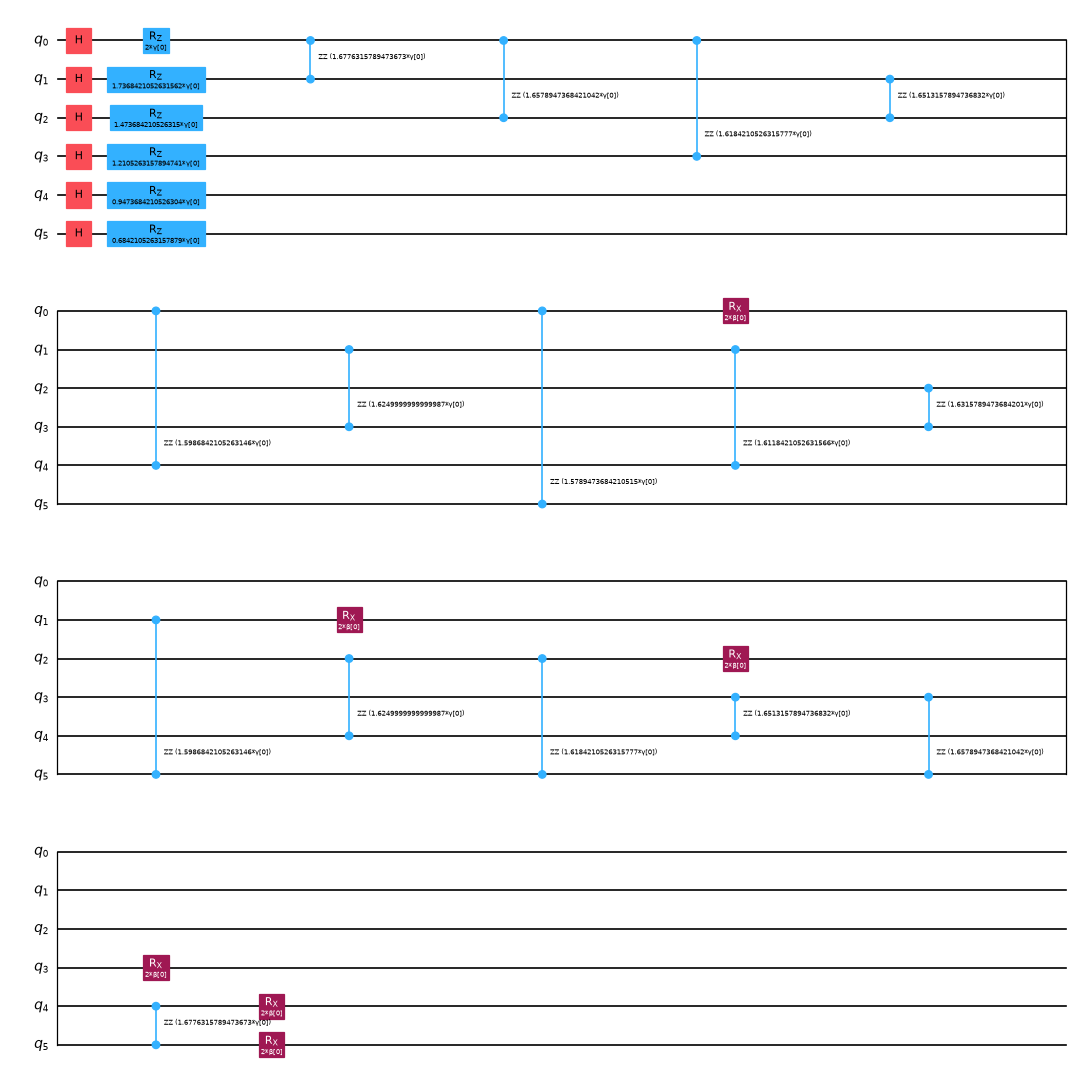

In [6]:
theta = np.random.default_rng(1).uniform(-1, 1, 6)   # [gamma_1..gamma_3, beta_1..beta_3]
print("|<this circuit | Qiskit QAOAAnsatz>| at p = 3:", round(pq.overlap_with_qaoa_ansatz(pq.QAOA(H, 3, "x"), theta), 12))
pq.QAOA(H, p=1, mixer="x").circuit().draw("mpl", fold=26, scale=0.6)

## 6. Training: several starts, keep the lowest energy

The classical optimizer (COBYLA) adjusts the $2p$ angles to minimize the expected cost

$$E(\gamma,\beta) = \langle\psi|H|\psi\rangle = \sum_x P_{\gamma,\beta}(x)\,F_A(x) - C,$$

computed exactly from the statevector, so there is no shot noise during training. The energy landscape has many valleys, and one run can get stuck (as in the Max-Cut tutorial). At every depth $p = 1, \dots, 5$ we therefore run:

- **5 random starts**, and look at the spread, not just the best;
- **1 layerwise start**: the best angles from depth $p-1$, stretched to $p$ layers (at $p = 1$, a linear ramp). Part 2 describes this in detail.

At each depth we keep the run with the **lowest energy**. We do not pick by $P_\text{opt}$: on a real problem the optimum is unknown, but the energy is always available.

The table's columns are:
- $P_\text{feas}$: probability that one shot is a valid portfolio. A random bitstring gives $20/64 = 0.31$.
- $P_\text{opt}$: probability that it is the best portfolio, ABC. A random bitstring gives $1/64 = 0.016$.
- quality: $\dfrac{f_\text{worst} - \mathbb{E}[f \mid \text{valid}]}{f_\text{worst} - f^*}$, which is 1 if every valid shot is ABC and 0 if every valid shot is the worst valid portfolio.

In [7]:
DEPTHS = [1, 2, 3, 4, 5]
runs = {A: pq.depth_scan(ex, H, DEPTHS, mixer="x", penalty=A, n_random=5, seed=0)}
chosen = pq.best_by_energy(runs[A])
print(pq.table([{"p": p, "start": r.start, "energy": r.energy, "P_feas": r.P_feas, "P_opt": r.P_opt,
                 "quality": r.quality} for p, r in chosen.items()]))

p      start  energy  P_feas  P_opt  quality
-  ---------  ------  ------  -----  -------
1       ramp  -2.646   0.578  0.032    0.596
2  layerwise  -3.019   0.575  0.036    0.616
3  layerwise  -3.228   0.563  0.061    0.696
4  layerwise  -3.452   0.675  0.123    0.777
5   random 5  -3.812   0.493  0.305    0.951


## 7. Measure and decode

We run the chosen depth-5 circuit 4096 times with Qiskit's `StatevectorSampler`. Each shot returns a key such as `'000111'`. Qiskit puts qubit 0 in the **rightmost** character, so `'000111'` means funds A, B and C. We then keep only valid portfolios and rank them by the original objective $f$, not by how often they appeared.

In [8]:
best = chosen[5]
counts = pq.QAOA(H, best.p, "x").sample(best.theta, shots=4096, seed=7)
print(pq.table(pq.decode_counts(counts, ex, top=8)))

m = pq.metrics(counts, ex)
se = np.sqrt(m["P_opt"] * (1 - m["P_opt"]) / counts.sum())
valid_seen = np.flatnonzero(ex.feasible & (counts > 0))
best_seen = valid_seen[np.argmin(ex.f[valid_seen])]
print(f"\nfrom shots: P_feas = {m['P_feas']:.3f}, P_opt = {m['P_opt']:.3f} ± {se:.3f}"
      f"   (exact: {best.P_feas:.3f}, {best.P_opt:.3f})")
print(f"most frequent bitstring: {pq.assets(pf, ex.X[np.argmax(counts)])} | "
      f"best valid portfolio sampled: {pq.assets(pf, ex.X[best_seen])} | brute force: {ex.best}")

Qiskit key  assets  count  valid       f  optimal
----------  ------  -----  -----  ------  -------
    001111    ABCD   1264  False  -8.525    False
    000111     ABC   1259   True  -6.975     True
    001011     ABD    435   True  -6.808    False
    010111    ABCE    389  False  -8.267    False
    011011    ABDE    140  False  -8.033    False
    010011     ABE    129   True  -6.533    False
    001101     ACD     70   True  -6.533    False
    100011     ABF     44   True  -6.242    False

from shots: P_feas = 0.498, P_opt = 0.307 ± 0.007   (exact: 0.493, 0.305)
most frequent bitstring: ABCD | best valid portfolio sampled: ABC | brute force: ABC


The most frequent bitstring is ABCD, an invalid four-fund portfolio, just ahead of ABC. After filtering, the best valid portfolio in the samples is ABC, which matches brute force. Validity therefore has to be checked before an answer is read off, and the most frequent bitstring and the best sampled portfolio are different quantities. Finding ABC somewhere in the samples is also weak evidence on its own: a random valid guess finds it within 4096 tries with probability $1 - (19/20)^{4096} \approx 1$. For this reason we report $P_\text{opt}$.

## 8. How the penalty weight changes the result

We repeat the same training for $A = 1$ (below $A_{crit}$), $A = 4$ and $A = 8$, and plot the lowest-energy run at each depth.

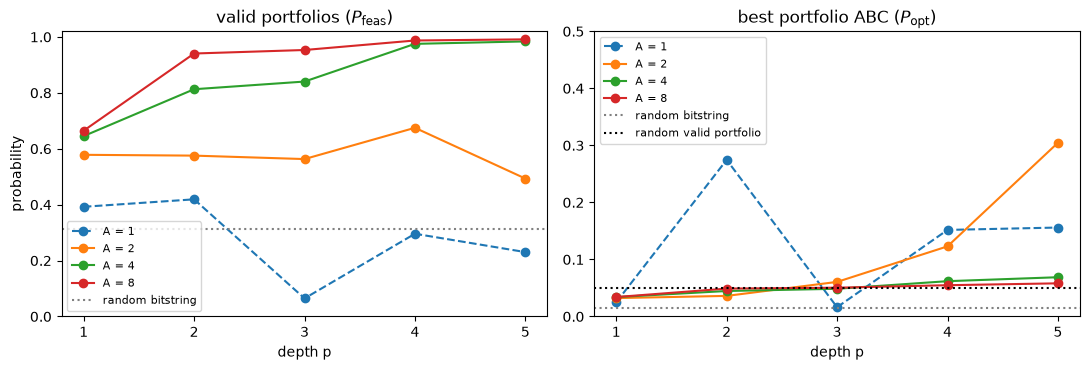

    A  P_feas p=1  P_feas p=2  P_feas p=3  P_feas p=4  P_feas p=5
-----  ----------  ----------  ----------  ----------  ----------
1.000       0.392       0.419       0.065       0.296       0.230
2.000       0.578       0.575       0.563       0.675       0.493
4.000       0.645       0.813       0.840       0.975       0.984
8.000       0.665       0.941       0.953       0.987       0.991 

    A  P_opt p=1  P_opt p=2  P_opt p=3  P_opt p=4  P_opt p=5
-----  ---------  ---------  ---------  ---------  ---------
1.000      0.025      0.275      0.016      0.152      0.156
2.000      0.032      0.036      0.061      0.123      0.305
4.000      0.034      0.045      0.049      0.062      0.069
8.000      0.034      0.049      0.050      0.055      0.058 



In [9]:
for A_value in [1.0, 4.0, 8.0]:
    H_A, _ = pq.cost_hamiltonian(pf, A_value)
    runs[A_value] = pq.depth_scan(ex, H_A, DEPTHS, mixer="x", penalty=A_value, n_random=5, seed=0)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for A_value in sorted(runs):
    chosen_A = pq.best_by_energy(runs[A_value])
    style = "--" if A_value < A_crit else "-"
    for ax, metric in zip(axes, ["P_feas", "P_opt"]):
        ax.plot(DEPTHS, [getattr(chosen_A[p], metric) for p in DEPTHS], style, marker="o", label=f"A = {A_value:g}")
axes[0].axhline(20 / 64, color="gray", ls=":", label="random bitstring")
axes[1].axhline(1 / 64, color="gray", ls=":", label="random bitstring")
axes[1].axhline(1 / 20, color="black", ls=":", label="random valid portfolio")
axes[0].set(title=r"valid portfolios ($P_\mathrm{feas}$)", xlabel="depth p", ylabel="probability", ylim=(0, 1.02))
axes[1].set(title=r"best portfolio ABC ($P_\mathrm{opt}$)", xlabel="depth p", ylim=(0, 0.5))
for ax in axes:
    ax.set_xticks(DEPTHS)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

for metric in ["P_feas", "P_opt"]:
    print(pq.table([{"A": A_value, **{f"{metric} p={p}": getattr(pq.best_by_energy(runs[A_value])[p], metric) for p in DEPTHS}}
                    for A_value in sorted(runs)]), "\n")

## 9. Results and reflection

**Validity.** Raising $A$ improves validity. At $p = 5$, $P_\text{feas}$ rises from 0.49 at $A = 2$ to 0.98 at $A = 4$ and 0.99 at $A = 8$.

**Probability of the optimum.** Raising $A$ does not help find the best portfolio. At $p = 5$, $P_\text{opt}$ falls from 0.31 at $A = 2$ to 0.07 at $A = 4$ and 0.06 at $A = 8$. This is close to picking a random valid portfolio (0.05): with a large penalty, the cost landscape is dominated by the number of funds held rather than by which funds are held.

**Below $A_{crit}$** ($A = 1$, dashed line), the results vary irregularly with depth, with $P_\text{opt}$ between 0.02 and 0.28, because the lowest-energy state itself is the invalid ABCD.

**Depth.** At $A = 2$, $P_\text{opt}$ grows from 0.03 at $p = 1$ to 0.31 at $p = 5$. At $A = 4$ and $A = 8$ it stays below 0.07 at every depth.

**Most frequent versus best valid.** These differ. At $A = 2$ and $p = 5$, the most frequent bitstring was the invalid ABCD, and the best valid sample was ABC.

**Reflection: the penalty weight is a modelling choice.**
- If it is too small, the "optimal" answer violates the agreed rule (here, by holding a fourth fund).
- If it is too large, the method no longer distinguishes good portfolios from mediocre ones, even though almost every sample is valid.
- $A_{crit}$ came from brute force, which is only possible because this instance is tiny. The answer-free bound demands $A > 5.24$, deep in the regime where $P_\text{opt}$ collapses. A formulation that enforces the rule by construction avoids this trade-off; this is the first extension in Part 2.

**Limits.** With 6 funds and 64 bitstrings, every option can be checked classically in negligible time. This notebook shows that the encoding and the pipeline are correct; it does not claim a quantum advantage. All circuits are simulated exactly, without hardware noise.

*Built on B. Tirado's Max-Cut starter notebook (CC BY 4.0). References are listed at the end of Part 2.*